# Stage 2 — Sequential Risk-Matching & Pricing Optimizer

Estimate kernel-local risk and rival price pressure, apply the requested staged funnel to the Batch 2 backtest and Batch 3 pricing, and retain all Batch 3 IDs with missing rates for rejected applicants.


In [17]:
import math
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

RAW_DIR = Path('../data/raw')
PROCESSED_DIR = Path('../data/processed')
PRINCIPAL = 10_000.0
TASTE_DISCOUNT = 0.02
FUNNEL_RATE = 0.035           # Sequentially reject 3.4% of remaining applicants per stage
RISK_CUT_PERCENTILE = 1.0 - FUNNEL_RATE
PROFIT_CREAM_PERCENTILE = FUNNEL_RATE
N_RATES = 10                   # Granularity of adaptive candidate rate grid, make higher for full run
H_GRID = [0.005]#, 0.010, 0.015, 0.025] change for complete run
STRESS_DELTAS = [-0.01, 0.01]
WEIGHT_CUTOFF = 1e-2 # For run time efficiency, change to 1e-4
CHUNK_SIZE = 1000
print(f'Configuration initialized with adaptive rate grid and sequential {FUNNEL_RATE*100:.1f}% funnel.')

Configuration initialized with adaptive rate grid and sequential 3.5% funnel.


## 1. Load and validate inputs

Join applicant-level predicted PDs and diagnostic values on unique IDs. Confirm coverage and expose the limitations caused by missing rival quotes.

In [18]:
batch2 = pd.read_csv(PROCESSED_DIR / 'Batch2.csv')
batch2_pd = pd.read_csv(PROCESSED_DIR / 'batch2_p_default_catboost.csv')
batch3 = pd.read_csv(RAW_DIR / 'NewApplications_Lender3_Round2.csv')
# Load initial Stage 2 PDs as requested; keep all original IDs for final reconstruction.
batch3_pd = pd.read_csv(PROCESSED_DIR / 'batch3_p_default_catboost.csv')
diag = pd.read_csv(RAW_DIR / 'Round1_Diagnostic_33.csv')

for name, frame in [('Batch2', batch2), ('Batch2 PD', batch2_pd), ('Batch3', batch3), ('Batch3 PD', batch3_pd), ('diagnostic', diag)]:
    assert frame.id.is_unique, f'{name} IDs are not unique'
assert all(len(x) == 100_000 for x in [batch2, batch2_pd, batch3, batch3_pd, diag])

hist = batch2.merge(batch2_pd[['id', 'pd']].rename(columns={'pd': 'p_global'}), on='id', validate='one_to_one')
hist = hist.rename(columns={'p_global': 'p_hist'})
# Keep the unfiltered full population separate from the sequential working funnel.
original_ids = batch3[['id']].copy()
all_batch3 = batch3.merge(batch3_pd[['id', 'pd']].rename(columns={'pd': 'p_default'}), on='id', validate='one_to_one')
assert len(all_batch3) == 100_000 and all_batch3.id.is_unique
assert all_batch3.p_default.between(0, 1).all()

assert hist.p_hist.between(0, 1).all()
assert hist.default.isin([0, 1]).all() and hist.accepted.isin([0, 1]).all()
comp_mask = hist[['competing1', 'competing2']].notna().all(axis=1).to_numpy()
print(f'Batch 2: {len(hist):,} labeled; complete rival quotes: {comp_mask.sum():,} ({comp_mask.mean():.1%})')
print(f'Observed accepted/won rate={hist.accepted.mean():.2%}; default among accepted={hist.loc[hist.accepted.eq(1), "default"].mean():.2%}')
print(f'Observed Stage 1 diagnostic profit: €{hist.profit.sum():,.0f}')


Batch 2: 100,000 labeled; complete rival quotes: 49,177 (49.2%)
Observed accepted/won rate=49.16%; default among accepted=12.25%
Observed Stage 1 diagnostic profit: €30,908,296


## 2. Kernel risk and market-choice functions

Use normalized Gaussian weights `exp(-0.5*((p_query-p_ref)/h)^2)`. A KD-tree radius includes all observations with raw weight ≥1e-4; excluded weights are smaller. Risk is estimated over all labeled Batch 2 cases; competitive probabilities use local neighbors among complete rival quotes, with their weights renormalized. Strict undercut conditions match the user-provided specification.

In [19]:
def build_tree(reference_pd, h, cutoff=WEIGHT_CUTOFF):
    ref = np.asarray(reference_pd, dtype=float)
    tree = cKDTree(ref.reshape(-1, 1))
    radius = h * math.sqrt(2 * math.log(1 / cutoff))
    return ref, tree, radius

def kernel_neighbors(query_pd, ref_pd, tree, radius, h):
    q = np.asarray(query_pd, dtype=float)
    groups = tree.query_ball_point(q.reshape(-1, 1), r=radius)
    result = []
    for qi, inds in zip(q, groups):
        inds = np.asarray(inds, dtype=np.int32)
        w = np.exp(-0.5 * ((qi - ref_pd[inds]) / h) ** 2)
        total = w.sum()
        if total <= 0 or not np.isfinite(total):
            inds = np.array([int(np.argmin(np.abs(ref_pd - qi)))], dtype=np.int32)
            w = np.ones(1); total = 1.0
        result.append((inds, w / total))
    return result

def get_adaptive_rate_grid(rival1, rival2, p_local, n_points=10, buffer=0.01, rng=None):
    """Return applicant rate grid bounded below by breakeven and a toxic-market flag."""
    r1 = np.asarray(rival1, dtype=float)
    r2 = np.asarray(rival2, dtype=float)
    rng = np.random.default_rng() if rng is None else rng
    r1 = r1[np.isfinite(r1)]; r2 = r2[np.isfinite(r2)]
    r1_sample = rng.choice(r1, size=max(1, int(np.sqrt(len(r1)))), replace=False) if len(r1) else np.array([])
    r2_sample = rng.choice(r2, size=max(1, int(np.sqrt(len(r2)))), replace=False) if len(r2) else np.array([])
    sampled = np.concatenate([r1_sample, r2_sample])
    breakeven = p_local / (1.0 - p_local)
    if not len(sampled):
        r_min = breakeven
        r_max = min(1.0, r_min + 0.05)
        return np.linspace(r_min, r_max, n_points), False

    c_max = float(sampled.max())
    market_below_breakeven = bool(breakeven > c_max)
    r_min = max(breakeven, float(sampled.min()) - buffer)
    r_max = min(1.0, max(c_max + buffer, r_min + 0.05))
    return np.linspace(r_min, r_max, n_points), market_below_breakeven

def scenario_pwin_exact(rate, rival1, rival2, delta=0.0):
    """P(Win) for one specific rival pair under equal borrower preference types."""
    c1 = float(rival1) * (1.0 + delta)
    c2 = float(rival2) * (1.0 + delta)
    r = np.asarray(rate, dtype=float)
    win1 = (r < c1 - TASTE_DISCOUNT) & (r < c2)
    win2 = (r < c1) & (r < c2 - TASTE_DISCOUNT)
    win3 = (r - TASTE_DISCOUNT < c1) & (r - TASTE_DISCOUNT < c2)
    return (win1.astype(float) + win2.astype(float) + win3.astype(float)) / 3.0

def expected_profit(rate_grid, p_local, p_win):
    """P(Win) * €10,000 * [(1 - p_local) * rate - p_local]."""
    r = np.asarray(rate_grid, dtype=float)
    return np.asarray(p_win) * PRINCIPAL * ((1.0 - p_local) * r - p_local)

def p_win_by_rate(rate_grid, rival1, rival2, weights, delta=0.0):
    """Mean P(Win) over lender-1, lender-2, and lender-3 preference types for a group of rivals."""
    c1 = np.asarray(rival1, dtype=float) * (1.0 + delta)
    c2 = np.asarray(rival2, dtype=float) * (1.0 + delta)
    r = np.asarray(rate_grid, dtype=float)[:, None]
    win1 = ((r < c1[None, :] - TASTE_DISCOUNT) & (r < c2[None, :])).astype(float)
    win2 = ((r < c1[None, :]) & (r < c2[None, :] - TASTE_DISCOUNT)).astype(float)
    win3 = ((r - TASTE_DISCOUNT < c1[None, :]) & (r - TASTE_DISCOUNT < c2[None, :])).astype(float)
    w = np.asarray(weights, dtype=float); w = w / w.sum()
    return ((win1 @ w) + (win2 @ w) + (win3 @ w)) / 3.0

## 3. Exploratory Analysis: Rival Pricing & Rate Distribution over Risk

Examine how Competitor 1 and Competitor 2 price loans as a function of credit risk in Batch 2. Notice that rival rates range well above 25% (up to ~95%), motivating the applicant-specific adaptive rate grid.

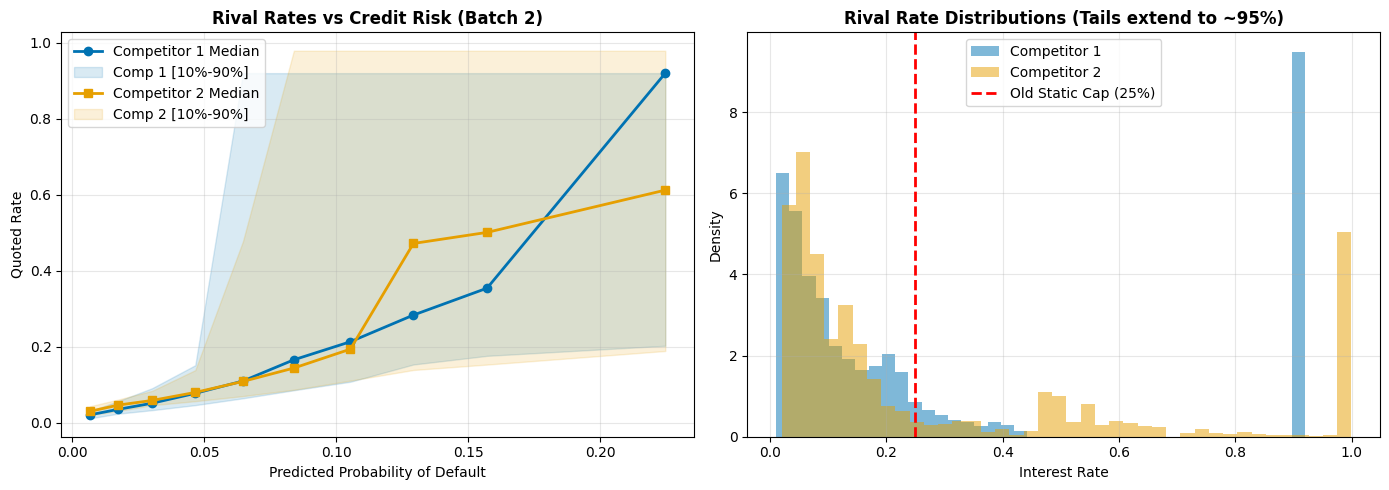

Rival quotes > 25%: Competitor 1=19,373 | Competitor 2=28,272
Max rates: Competitor 1=91.99% | Competitor 2=99.96%


In [20]:
# Plot distribution of competing1 and competing2 over P(Default) in Batch 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

hist_valid = hist.loc[comp_mask].copy()
hist_valid['risk_decile'] = pd.qcut(hist_valid['p_hist'], 10)
decile_summary = hist_valid.groupby('risk_decile', observed=False).agg(
    p_mean=('p_hist', 'mean'),
    c1_median=('competing1', 'median'),
    c1_p10=('competing1', lambda x: np.quantile(x, 0.10)),
    c1_p90=('competing1', lambda x: np.quantile(x, 0.90)),
    c2_median=('competing2', 'median'),
    c2_p10=('competing2', lambda x: np.quantile(x, 0.10)),
    c2_p90=('competing2', lambda x: np.quantile(x, 0.90))
)

ax = axes[0]
ax.plot(decile_summary.p_mean, decile_summary.c1_median, marker='o', label='Competitor 1 Median', color='#0072B2', lw=2)
ax.fill_between(decile_summary.p_mean, decile_summary.c1_p10, decile_summary.c1_p90, color='#0072B2', alpha=0.15, label='Comp 1 [10%-90%]')
ax.plot(decile_summary.p_mean, decile_summary.c2_median, marker='s', label='Competitor 2 Median', color='#E69F00', lw=2)
ax.fill_between(decile_summary.p_mean, decile_summary.c2_p10, decile_summary.c2_p90, color='#E69F00', alpha=0.15, label='Comp 2 [10%-90%]')
ax.set_title('Rival Rates vs Credit Risk (Batch 2)', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Probability of Default')
ax.set_ylabel('Quoted Rate')
ax.grid(True, alpha=0.3)
ax.legend()

ax = axes[1]
ax.hist(hist_valid['competing1'], bins=40, alpha=0.5, label='Competitor 1', color='#0072B2', density=True)
ax.hist(hist_valid['competing2'], bins=40, alpha=0.5, label='Competitor 2', color='#E69F00', density=True)
ax.axvline(0.25, color='red', linestyle='--', label='Old Static Cap (25%)', lw=2)
ax.set_title('Rival Rate Distributions (Tails extend to ~95%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Interest Rate')
ax.set_ylabel('Density')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print(f'Rival quotes > 25%: Competitor 1={(hist.competing1 > 0.25).sum():,} | Competitor 2={(hist.competing2 > 0.25).sum():,}')
print(f'Max rates: Competitor 1={hist.competing1.max():.2%} | Competitor 2={hist.competing2.max():.2%}')

## 4. Batch 2 Backtest: Full-cohort three-stage funnel

Run all 100,000 applicants through the CatBoost global-risk, local-risk, and profitability stages. Build local pricing references only from applicants with complete rival quotes; calculate realized win and P&L metrics only on those query rows as well.


In [21]:
hist_pd = hist.p_hist.to_numpy(float)
hist_default = hist.default.to_numpy(int)
hist_c1 = hist.competing1.to_numpy(float)
hist_c2 = hist.competing2.to_numpy(float)
bt = hist.reset_index(drop=True)
bt_pd = hist_pd
bt_global_pd = bt.p_hist.to_numpy(float)
bt_default = hist_default
bt_c1 = hist_c1
bt_c2 = hist_c2
quote_reference_idx = np.flatnonzero(comp_mask)

# comp_mask limits rival quote references and realized replay metrics; query population remains all 100,000.
def exact_top_fraction_mask(values, fraction):
    values = np.asarray(values, dtype=float)
    n_reject = int(np.floor(fraction * len(values)))
    mask = np.zeros(len(values), dtype=bool)
    if n_reject:
        mask[np.argsort(-values, kind='stable')[:n_reject]] = True
    return mask

def run_backtest(h, delta=0.0, show_progress=True):
    n = len(hist)
    if n != len(hist_pd) or n != len(comp_mask):
        raise ValueError('hist, hist_pd, and comp_mask must have matching full-population lengths')
    global_reject = exact_top_fraction_mask(hist_pd, FUNNEL_RATE)
    global_cutoff = float(np.quantile(hist_pd, 1.0 - FUNNEL_RATE))
    global_survivors = ~global_reject
    local = np.full(n, np.nan)
    bids = np.full(n, np.nan)
    maxev = np.full(n, np.nan)
    pwin_best = np.full(n, np.nan)
    rng = np.random.default_rng(42)
    ref = hist_pd[quote_reference_idx]
    ref_default = hist_default[quote_reference_idx]
    ref, tree, radius = build_tree(ref, h)

    # Stage 1: global PD cut over all Batch 2 applicants.
    # Stage 2: leave-one-out local PD only for Stage 1 survivors.
    chunks = range(0, n, CHUNK_SIZE)
    iterator = tqdm(chunks, total=math.ceil(n / CHUNK_SIZE), desc=f'Backtest h={h:.3f}, delta={delta:+.0%}: local PD', unit='1%') if show_progress else chunks
    for start in iterator:
        stop = min(start + CHUNK_SIZE, n)
        query_rows = np.flatnonzero(global_survivors[start:stop]) + start
        if not len(query_rows):
            continue
        neighbors = kernel_neighbors(hist_pd[query_rows], ref, tree, radius, h)
        for row, (ref_local_idx, weights) in zip(query_rows, neighbors):
            keep = quote_reference_idx[ref_local_idx] != row
            ref_local_idx = ref_local_idx[keep]
            weights = weights[keep]
            if len(ref_local_idx):
                weights = weights / weights.sum()
                local[row] = float(weights @ ref_default[ref_local_idx])
        del neighbors

    if not np.isfinite(local[global_survivors]).all():
        raise ValueError('Local PD missing for one or more Stage 1 Batch 2 survivors')
    risk_cutoff = float(np.quantile(local[global_survivors], 1.0 - FUNNEL_RATE))
    risk_reject = np.zeros(n, dtype=bool)
    risk_reject[global_survivors] = exact_top_fraction_mask(local[global_survivors], FUNNEL_RATE)
    local_survivors = global_survivors & ~risk_reject

    # Stage 3: price Stage 2 survivors; neighbor quotes come only from quote-complete references.
    toxic_market_count = 0
    chunks = range(0, n, CHUNK_SIZE)
    iterator = tqdm(chunks, total=math.ceil(n / CHUNK_SIZE), desc=f'Backtest h={h:.3f}, delta={delta:+.0%}: pricing', unit='1%') if show_progress else chunks
    for start in iterator:
        stop = min(start + CHUNK_SIZE, n)
        query_rows = np.flatnonzero(local_survivors[start:stop]) + start
        if not len(query_rows):
            continue
        neighbors = kernel_neighbors(hist_pd[query_rows], ref, tree, radius, h)
        for row, (ref_local_idx, weights) in zip(query_rows, neighbors):
            ref_rows = quote_reference_idx[ref_local_idx]
            # Exclude self from historical replay if the query itself is in the reference pool.
            keep = ref_rows != row
            ref_rows = ref_rows[keep]
            weights = weights[keep]
            if not len(ref_rows):
                continue
            rates, market_below_breakeven = get_adaptive_rate_grid(
                hist_c1[ref_rows], hist_c2[ref_rows], local[row], n_points=N_RATES, rng=rng
            )
            if market_below_breakeven:
                toxic_market_count += 1
            pwin_est = p_win_by_rate(rates, hist_c1[ref_rows], hist_c2[ref_rows], weights, delta=delta)
            ev = expected_profit(rates, local[row], pwin_est)
            best = int(np.argmax(ev))
            maxev[row] = ev[best]
            pwin_best[row] = pwin_est[best]
            bids[row] = rates[best]
        del neighbors
    print(f"Diagnostic: {toxic_market_count} applicants had competitor maximum rates strictly below our breakeven floor.")

    priced_survivors = local_survivors & np.isfinite(maxev)
    if not priced_survivors.any():
        raise ValueError('No Stage 2 Batch 2 applicants had usable quote-complete references for pricing')
    profit_cutoff = max(0.0, float(np.quantile(maxev[priced_survivors], 0.035)))
    print(f'Stage 3 expected-profit cutoff applied: €{profit_cutoff:.2f}')
    profit_reject = priced_survivors & (maxev <= profit_cutoff)
    bids[~priced_survivors | global_reject | risk_reject | profit_reject] = np.nan

    # Backtest outcomes are observable only for query applicants with both rival quotes.
    quote_complete = comp_mask
    c1 = hist_c1[quote_complete] * (1.0 + delta)
    c2 = hist_c2[quote_complete] * (1.0 + delta)
    typ = bt.borrowertype.to_numpy(int)[quote_complete]
    bids_complete = bids[quote_complete]
    own_effective = bids_complete.copy(); own_effective[typ == 3] -= TASTE_DISCOUNT
    rival1_effective = c1.copy(); rival1_effective[typ == 1] -= TASTE_DISCOUNT
    rival2_effective = c2.copy(); rival2_effective[typ == 2] -= TASTE_DISCOUNT
    won_complete = np.isfinite(bids_complete) & (own_effective < rival1_effective) & (own_effective < rival2_effective)
    defaults_complete = bt_default[quote_complete]
    realized = np.where(won_complete, PRINCIPAL * ((1.0 - defaults_complete) * bids_complete - defaults_complete), 0.0)
    d_rate = float(defaults_complete[won_complete].mean()) if won_complete.any() else np.nan

    return {'h': h, 'delta': delta, 'global_risk_cutoff': global_cutoff,
            'risk_cutoff': risk_cutoff, 'profit_cutoff': profit_cutoff,
            'n_applicants': n, 'n_quote_complete': int(quote_complete.sum()),
            'n_stage1_rejected': int(global_reject.sum()),
            'n_stage2_rejected': int(risk_reject.sum()),
            'n_stage3_rejected': int(profit_reject.sum()),
            'n_priced_full_cohort': int(np.isfinite(bids).sum()),
            'n_bids': int(np.isfinite(bids_complete).sum()),
            'n_won': int(won_complete.sum()),
            'win_rate_among_complete': float(won_complete.mean()),
            'default_rate_won': d_rate, 'total_profit_eur': float(realized.sum()),
            'mean_rate_won': float(bids_complete[won_complete].mean()) if won_complete.any() else np.nan,
            'bids': bids, 'local_risk': local, 'expected_profit': maxev,
            'p_win_at_optimum': pwin_best, 'won': won_complete}

backtests = []
for h in H_GRID:
    result = run_backtest(h)
    backtests.append(result)
    print({k: v for k, v in result.items() if k not in {'bids', 'local_risk', 'expected_profit', 'p_win_at_optimum', 'won'}})
backtest_summary = pd.DataFrame([{k: v for k, v in r.items() if k not in {'bids', 'local_risk', 'expected_profit', 'p_win_at_optimum', 'won'}} for r in backtests])
display(backtest_summary)


Backtest h=0.005, delta=+0%: local PD:   0%|          | 0/100 [00:00<?, ?1%/s]

Backtest h=0.005, delta=+0%: pricing:   0%|          | 0/100 [00:00<?, ?1%/s]

Diagnostic: 0 applicants had competitor maximum rates strictly below our breakeven floor.
Stage 3 expected-profit cutoff applied: €0.00
{'h': 0.005, 'delta': 0.0, 'global_risk_cutoff': 0.2548626967400678, 'risk_cutoff': 0.21518124622751883, 'profit_cutoff': 0.0, 'n_applicants': 100000, 'n_quote_complete': 49177, 'n_stage1_rejected': 3500, 'n_stage2_rejected': 3377, 'n_stage3_rejected': 74860, 'n_priced_full_cohort': 18263, 'n_bids': 18263, 'n_won': 11764, 'win_rate_among_complete': 0.23921752038554608, 'default_rate_won': 0.12342740564433866, 'total_profit_eur': 21069683.183972813, 'mean_rate_won': 0.36157542167248063}


,h,delta,global_risk_cutoff,risk_cutoff,profit_cutoff,n_applicants,n_quote_complete,n_stage1_rejected,n_stage2_rejected,n_stage3_rejected,n_priced_full_cohort,n_bids,n_won,win_rate_among_complete,default_rate_won,total_profit_eur,mean_rate_won
0,0.005,0.0,0.254863,0.215181,0.0,100000,49177,3500,3377,74860,18263,18263,11764,0.239218,0.123427,2.106968e+07,0.361575


## 5. Select bandwidth and stress-test competitor rates

Choose the bandwidth with the largest realized Batch 2 replay P&L. Then replay at ±1% relative competitor-rate shifts. These sensitivity cases alter rivals' observed quotes but preserve all other assumptions.

In [ ]:
best_idx=int(backtest_summary.total_profit_eur.idxmax())
SELECTED_H=float(backtest_summary.loc[best_idx,'h'])
selected_backtest=backtests[best_idx]
print(f'Selected h={SELECTED_H:.3f}; backtest P&L €{selected_backtest["total_profit_eur"]:,.0f}; won-loan default rate {selected_backtest["default_rate_won"]:.2%}')
stress=[]
for delta in STRESS_DELTAS:
    r=run_backtest(SELECTED_H,delta=delta)
    stress.append({k:v for k,v in r.items() if k not in {'bids','local_risk','expected_profit','p_win_at_optimum','won'}})
stress_summary=pd.DataFrame(stress)
display(stress_summary)

## 6. Sequential Batch 3 funnel: global risk, local risk, expected profit

Each stage rejects exactly 3.5% of the applicants currently remaining (using rank-based selection so ties do not change the count). Stage 1 uses CatBoost PD and runs before any KD-tree work. Stage 2 computes local kernel PD only for Stage 1 survivors. Stage 3 prices only Stage 2 survivors, then removes applicants below the 3.5th percentile of their expected profits. The final result is reconstructed against all original IDs with `interest_rate = NaN` for every rejection.


In [ ]:
# Stage 1: initial global CatBoost risk cut (before any local risk or rate work).
work = all_batch3[['id', 'p_default']].copy().reset_index(drop=True)
cutoff_stage1 = float(work.p_default.quantile(1.0 - FUNNEL_RATE))
reject1_mask = exact_top_fraction_mask(work.p_default.to_numpy(), FUNNEL_RATE)
rejected_stage1 = work.loc[reject1_mask, 'id'].copy()
work = work.loc[~reject1_mask].reset_index(drop=True)
print(f'Stage 1 global PD 96.5th percentile: {cutoff_stage1:.6f}; rejected {len(rejected_stage1):,}; remaining {len(work):,}')
assert len(rejected_stage1) == int(np.floor(FUNNEL_RATE * len(all_batch3)))

# Stage 2: local kernel risk only for Stage 1 survivors.
local_risk_stage2 = precompute_local_risk(
    work.p_default.to_numpy(), hist_pd, hist_default, SELECTED_H,
    show_progress=True, label='Stage 2 local risk (Stage 1 survivors)'
)
work['local_pd'] = local_risk_stage2
assert work.local_pd.notna().all(), 'Local risk missing for one or more Stage 1 survivors'
cutoff_stage2 = float(work.local_pd.quantile(1.0 - FUNNEL_RATE))
reject2_mask = exact_top_fraction_mask(work.local_pd.to_numpy(), FUNNEL_RATE)
rejected_stage2 = work.loc[reject2_mask, 'id'].copy()
work = work.loc[~reject2_mask].reset_index(drop=True)
print(f'Stage 2 local PD 96.5th percentile: {cutoff_stage2:.6f}; rejected {len(rejected_stage2):,}; remaining {len(work):,}')
assert len(rejected_stage2) == int(np.floor(FUNNEL_RATE * (len(all_batch3) - len(rejected_stage1))))

# Stage 3: expected profit and optimal rates only for Stage 2 survivors.
def price_survivors(survivors, h, show_progress=True):
    q = survivors.p_default.to_numpy(dtype=float)
    n = len(q)
    result_rate = np.full(n, np.nan)
    result_profit = np.full(n, np.nan)
    result_pwin = np.full(n, np.nan)
    rng = np.random.default_rng(42)
    toxic_market_count = 0
    ref, tree, radius = build_tree(hist_pd, h)
    chunks = range(0, n, CHUNK_SIZE)
    iterator = tqdm(chunks, total=math.ceil(n / CHUNK_SIZE), desc='Stage 3 pricing (survivors)', unit='1%') if show_progress else chunks
    for start in iterator:
        stop = min(start + CHUNK_SIZE, n)
        matches = kernel_neighbors(q[start:stop], ref, tree, radius, h)
        for offset, (inds, weights) in enumerate(matches):
            row = start + offset
            cm = comp_mask[inds]
            cinds = inds[cm]
            if not len(cinds):
                continue
            cw = weights[cm]
            cw = cw / cw.sum()
            local_pd = float(survivors.iloc[row].local_pd)
            rates, market_below_breakeven = get_adaptive_rate_grid(
                hist_c1[cinds], hist_c2[cinds], local_pd, n_points=N_RATES, rng=rng
            )
            if market_below_breakeven:
                toxic_market_count += 1
            pwin = p_win_by_rate(rates, hist_c1[cinds], hist_c2[cinds], cw)
            ev = expected_profit(rates, local_pd, pwin)
            best = int(np.argmax(ev))
            result_rate[row] = rates[best]
            result_profit[row] = ev[best]
            result_pwin[row] = pwin[best]
        del matches
    print(f"Diagnostic: {toxic_market_count} applicants had competitor maximum rates strictly below our breakeven floor.")
    return pd.DataFrame({'id': survivors.id.to_numpy(),
                         'expected_profit': result_profit,
                         'optimal_interest_rate': result_rate,
                         'p_win_at_optimum': result_pwin})

priced_stage3 = price_survivors(work, SELECTED_H, show_progress=True)
work = work.merge(priced_stage3, on='id', how='left', validate='one_to_one')
assert work.expected_profit.notna().all(), 'Expected profit missing for one or more Stage 2 survivors'
cutoff_stage3 = float(work.expected_profit.quantile(FUNNEL_RATE))
print(f'Stage 3 expected-profit 3.5th percentile: €{cutoff_stage3:,.2f}')
if cutoff_stage3 > 100.0:
    print('⚠️ WARNING: 3.5% profit threshold is above 100€')

reject3_mask = work.expected_profit < cutoff_stage3
rejected_stage3 = work.loc[reject3_mask, 'id'].copy()
work_survivors = work.loc[~reject3_mask].copy()
print(f'Stage 3 rejected {len(rejected_stage3):,}; final survivors {len(work_survivors):,}')

# Reconstruct the full 100,000-ID result. Rejected IDs and any non-survivors have NaN interest_rate.
final_rates = work_survivors[['id', 'optimal_interest_rate']].rename(columns={'optimal_interest_rate': 'interest_rate'})
final_output = original_ids.merge(final_rates, on='id', how='left', validate='one_to_one')
final_output['interest_rate'] = final_output['interest_rate'].astype(float)

rejected_all = pd.Index(pd.concat([rejected_stage1, rejected_stage2, rejected_stage3], ignore_index=True))
assert len(final_output) == 100_000 and final_output.id.is_unique
assert set(final_output.id) == set(original_ids.id)
assert final_output.loc[final_output.id.isin(rejected_all), 'interest_rate'].isna().all()
assert final_output.loc[final_output.id.isin(work_survivors.id), 'interest_rate'].notna().all()
print(f'Final output rows: {len(final_output):,}; priced: {final_output.interest_rate.notna().sum():,}; blank/NaN rate: {final_output.interest_rate.isna().sum():,}')
print(f'Rejection counts — Stage 1: {len(rejected_stage1):,}; Stage 2: {len(rejected_stage2):,}; Stage 3: {len(rejected_stage3):,}')


In [ ]:
# Funnel diagnostics: retained local-risk and expected-profit distributions, plus final rates.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(all_batch3.p_default, bins=50, color='#0072B2', alpha=0.55)
axes[0].axvline(cutoff_stage1, color='darkred', linestyle='--', label=f'Stage 1 cutoff={cutoff_stage1:.1%}')
axes[0].set_title('Initial CatBoost PD distribution'); axes[0].set_xlabel('CatBoost PD'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].hist(work_survivors.local_pd, bins=50, color='#009E73', alpha=0.6)
axes[1].axvline(cutoff_stage2, color='darkred', linestyle='--', label=f'Stage 2 cutoff={cutoff_stage2:.1%}')
axes[1].set_title('Stage 2 survivor local PD'); axes[1].set_xlabel('Local kernel PD'); axes[1].legend(); axes[1].grid(alpha=.3)
axes[2].scatter(work_survivors.local_pd, work_survivors.optimal_interest_rate, alpha=.12, s=5, color='#CC79A7')
axes[2].set_title('Final rates by local risk'); axes[2].set_xlabel('Local kernel PD'); axes[2].set_ylabel('Interest rate'); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()


## 7. Check benchmark gates and export

The required deliverable is a two-column CSV with `id, rate`; rejected applicants remain present with missing rates for auditability. A second detailed file retains the inputs and optimization diagnostics. Export a concise backtest and stress-test summary as well.

In [ ]:
TARGET_PROFIT_EUR=30_900_000
TARGET_DEFAULT_RATE=0.1225
bt_profit=float(selected_backtest['total_profit_eur'])
bt_default=float(selected_backtest['default_rate_won']) if np.isfinite(selected_backtest['default_rate_won']) else np.nan
gate_report=pd.DataFrame([
 {'gate':'Backtest P&L exceeds €30.9M','observed':bt_profit,'threshold':TARGET_PROFIT_EUR,'pass':bt_profit>TARGET_PROFIT_EUR},
 {'gate':'Won-loan default rate below 12.25%','observed':bt_default,'threshold':TARGET_DEFAULT_RATE,'pass':np.isfinite(bt_default) and bt_default<TARGET_DEFAULT_RATE},
])
gate_report['sample_n']=[selected_backtest['n_quote_complete'],selected_backtest['n_won']]
display(gate_report)
print(f"Benchmark covers {selected_backtest['n_quote_complete']:,} of 100,000 Batch 2 cases with complete rival quotes.")

final_output.rename(columns={'interest_rate':'rate'}).to_csv(PROCESSED_DIR/'batch3_lender3_rates_stage2.csv',index=False)
final_output.to_csv(PROCESSED_DIR/'batch3_lender3_rates_stage2_audit.csv',index=False)
backtest_summary.to_csv(PROCESSED_DIR/'stage2_bandwidth_backtest.csv',index=False)
stress_summary.to_csv(PROCESSED_DIR/'stage2_competitor_stress_test.csv',index=False)
gate_report.to_csv(PROCESSED_DIR/'stage2_backtest_gates.csv',index=False)
rejection_audit = pd.DataFrame({'id': pd.concat([rejected_stage1, rejected_stage2, rejected_stage3], ignore_index=True),
                                'rejected_stage': (['stage1'] * len(rejected_stage1) + ['stage2'] * len(rejected_stage2) + ['stage3'] * len(rejected_stage3))})
rejection_audit.to_csv(PROCESSED_DIR/'batch3_stage_rejection_audit.csv',index=False)
print('Wrote Stage 2 bid CSV, audit, bandwidth, stress-test, gate, and rejection-audit files.')